# Step 4: Exploring the data

**Question:** At Torrey Pines, is it more rewarding to hit it farther and miss more fairways, or hit it shorter and find more fairways? How does that compare with a typical PGA TOUR event?

Before running any regressions, we look at the data: how big it is, what typical values are, and whether Torrey looks different from other events. Each code cell has a plain-English note above it.

### 1. Load the libraries and the tidy CSV
`pandas` holds the table, `matplotlib` draws charts. `pd.read_csv` loads the file we built in Step 3 into a table called `df` (short for "data frame"). The path starts with `../` because this notebook lives in `notebooks/`, one folder below the project root.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

df = pd.read_csv("../data/clean/pga_event_stats.csv")
print(f"{len(df):,} rows (player-events), {df['tournament_id'].nunique()} events, {df['player_id'].nunique():,} players")
df.head()

29,635 rows (player-events), 424 events, 1,037 players


,player,player_id,year,event,tournament_id,is_torrey,distance,fairway_pct,sg_total,sg_t2g,sg_ott,sg_rounds
0,Alex Moon,39356,2017,AT&T Byron Nelson,R2017019,0,275.1,42.86,-0.632,-1.226,-1.228,4.0
1,Beau Hossler,35461,2017,AT&T Byron Nelson,R2017019,0,289.5,60.71,-0.382,0.168,1.325,4.0
2,Billy Horschel,29420,2017,AT&T Byron Nelson,R2017019,0,305.0,57.14,3.618,1.522,0.657,4.0
3,Billy Hurley III,29222,2017,AT&T Byron Nelson,R2017019,0,265.8,39.29,0.618,-0.506,-1.874,4.0
4,Bob Estes,1320,2017,AT&T Byron Nelson,R2017019,0,271.0,57.14,-1.132,-0.850,-1.392,4.0


### 2. Keep the rows we can use in the regression
Some events (the Masters, The Open, small opposite-field events) have no strokes-gained data, because PGA TOUR's shot tracking (ShotLink) isn't used there. `dropna` removes rows with a missing value in the listed columns. We also add a readable `group` label.

In [2]:
df = df.dropna(subset=["distance", "fairway_pct", "sg_total"]).copy()
df["group"] = df["is_torrey"].map({1: "Torrey Pines", 0: "Other events"})
df["group"].value_counts()

group
Other events    24798
Torrey Pines      760
Name: count, dtype: int64

### 3. Summary statistics: Torrey vs. other events
`groupby("group")` splits the table into the two groups, and `.agg([...])` computes the mean, standard deviation, min and max of each stat within each group.

In [3]:
stats = ["distance", "fairway_pct", "sg_total", "sg_t2g", "sg_ott"]
summary = df.groupby("group")[stats].agg(["mean", "std", "min", "max"]).round(2)
summary.T   # .T flips rows and columns so it's easier to read

group             Other events  Torrey Pines
distance    mean        300.47        297.68
            std          14.21         11.45
            min         242.60        262.90
            max         363.10        331.90
fairway_pct mean         61.70         52.95
            std          10.75          8.90
            min          19.64         26.79
            max          98.21         82.14
sg_total    mean          0.73          0.65
            std           1.34          1.57
            min          -5.96         -4.28
            max           6.53          5.07
sg_t2g      mean          0.49          0.39
            std           1.16          1.32
            min          -6.01         -5.37
            max           5.17          4.15
sg_ott      mean          0.12          0.09
            std           0.60          0.62
            min          -4.08         -2.20
            max           2.22          2.21

**Reading it:** at Torrey, players hit about **9 percentage points fewer fairways** than at a typical event, with about the same driving distance. Strokes gained averages are above zero in both groups because the tables mostly include players who made the cut (the better performers that week).

### 4. Do longer hitters miss more fairways? (correlations)
A correlation runs from -1 to +1. A negative number between `distance` and `fairway_pct` means longer hitters tend to hit fewer fairways, which is the trade-off this project is about. We compute it separately for each group.

In [4]:
for name, g in df.groupby("group"):
    print(name)
    print(g[["distance", "fairway_pct", "sg_total", "sg_ott"]].corr().round(2), "\n")

Other events
             distance  fairway_pct  sg_total  sg_ott
distance         1.00        -0.23      0.13    0.31
fairway_pct     -0.23         1.00      0.14    0.30
sg_total         0.13         0.14      1.00    0.41
sg_ott           0.31         0.30      0.41    1.00 

Torrey Pines
             distance  fairway_pct  sg_total  sg_ott
distance         1.00        -0.29      0.16    0.50
fairway_pct     -0.29         1.00      0.16    0.27
sg_total         0.16         0.16      1.00    0.39
sg_ott           0.50         0.27      0.39    1.00 



### 5. Scatter plot: distance vs. fairway %, colored by strokes gained
Each dot is one player at one event. Left panel: all other events. Right panel: Torrey Pines, drawn over a faint gray copy of the other events so you can compare. Color shows **strokes gained: total** that week: **blue = gained strokes (good)**, **red = lost strokes**, gray = about average. Colors are capped at ±3 so a few extreme weeks don't wash out everything else. The black cross marks each group's average.

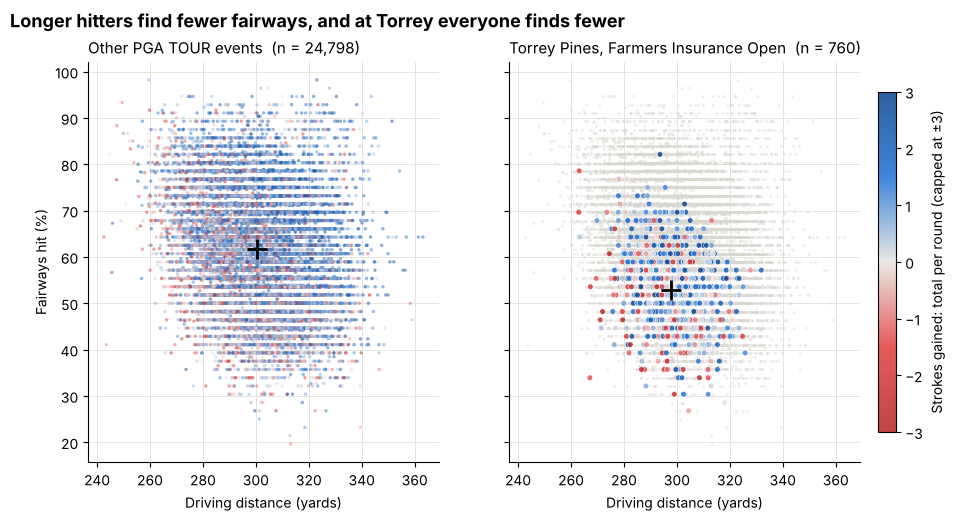

In [5]:
# A diverging color scale: red (lost strokes) -> light gray (zero) -> blue (gained strokes)
cmap = LinearSegmentedColormap.from_list("sg", ["#b8322f", "#e34948", "#e8e7e2", "#2a78d6", "#184f95"])
norm = TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3)   # makes 0 the exact middle of the scale

other = df[df["is_torrey"] == 0]
torrey = df[df["is_torrey"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)

# Left: other events
axes[0].scatter(other["distance"], other["fairway_pct"], c=other["sg_total"], cmap=cmap, norm=norm,
                s=6, alpha=0.5, linewidths=0)
axes[0].set_title(f"Other PGA TOUR events  (n = {len(other):,})", loc="left", fontsize=11)

# Right: Torrey on top of a faint gray background of all other events
axes[1].scatter(other["distance"], other["fairway_pct"], color="#d8d7d0", s=5, alpha=0.4, linewidths=0)
points = axes[1].scatter(torrey["distance"], torrey["fairway_pct"], c=torrey["sg_total"], cmap=cmap, norm=norm,
                         s=16, alpha=0.9, edgecolors="white", linewidths=0.4)
axes[1].set_title(f"Torrey Pines, Farmers Insurance Open  (n = {len(torrey):,})", loc="left", fontsize=11)

for ax, g in zip(axes, [other, torrey]):
    ax.plot(g["distance"].mean(), g["fairway_pct"].mean(), marker="+", color="black", markersize=14, mew=2)
    ax.set_xlabel("Driving distance (yards)")
    ax.grid(color="#e1e0d9", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Fairways hit (%)")

bar = fig.colorbar(points, ax=axes, shrink=0.85, pad=0.02)
bar.set_label("Strokes gained: total per round (capped at ±3)")
fig.suptitle("Longer hitters find fewer fairways, and at Torrey everyone finds fewer",
             x=0.06, ha="left", fontsize=13, fontweight="bold")

fig.savefig("../figures/01_distance_vs_fairways.png", dpi=200, bbox_inches="tight")
plt.show()

### 6. What we see, and what it means for Step 5
1. **The trade-off is real.** In both panels the cloud slopes down: longer hitters hit fewer fairways (see the negative correlations above).
2. **Torrey shifts the whole cloud down.** Fairways are much harder to hit there, while distance is about the same.
3. **A first hint at the answer:** at Torrey, strokes gained off the tee is more closely tied to distance (correlation 0.50) than to fairways (0.27). At other events the two are about equal (0.31 vs. 0.30). That suggests distance pays off more at Torrey, but correlations don't hold the other variable fixed, so Step 5 tests it properly.
4. **Color is mixed across the cloud.** Blue and red dots appear at every distance and accuracy level, so neither stat alone decides a player's week. The regression in Step 5 will estimate how much each one is worth, holding the other fixed, and whether those values differ at Torrey.
5. **Watch for confounding.** Better players are often both long *and* accurate, so a simple regression mixes "skill" with "distance" and "accuracy". In Step 5 we'll add player fixed effects (comparing each player with himself) to deal with that.